# 06 — Phase 1b: Human Evaluation — PF Exercise Scoring

Score generated PF exercises using the Rahimi et al. (2025) rubric.
Rubric is displayed at the top for constant reference.

## Rahimi et al. (2025) Rubric — Reference Card

| Dimension | 1 (Low) | 2 (Moderate) | 3 (High) |
|---|---|---|---|
| **APK** Activation of Prior Knowledge | No prerequisite concepts | One prerequisite concept | Two or more prerequisite concepts |
| **SSC** Sweet Spot Calibration | Too easy or too difficult → disengagement | Moderate challenge with some failures | Well-calibrated: challenging but manageable, leading to productive engagement |
| **AE** Affective Engagement | Not relatable or meaningful; fails to engage | Somewhat engaging, with relatable/realistic elements | Highly engaging, meaningful narrative or real-world scenario |
| **MR** Multiple Representations & Solutions | Few or no representations or solution methods | Some diversity but limited | Wide range of representations and solution methods; fosters creativity |
| **OE** Open-endedness / Ill-structuredness | Simple, well-structured, single path | Moderate complexity with limited variables | Highly complex, requiring integration of multiple variables and representations |

**Calibration reference** (from Rahimi GPT-4o scores): Most exercises score **2-3** per dimension. SSC shows the most variance (SD=0.55). Total scores cluster at **13-15** for GPT-4o quality. Reserve score-1 for clear deficiencies.

**Scoring procedure:** Blind to version (V1/V2/V3). Score each dimension independently. Total = sum of 5 dimensions (5-15).

## 1. Setup & generate an experimentally usable DeepSeek pool

> The pool uses the same seven design briefs for V1, V2, and V3. It runs independent model calls in parallel, shows completion progress, retries malformed or exact-duplicate outputs, and saves the accepted pool to disk.

> **Expected workload:** 21 jobs in the first round. V3 jobs internally make two model calls, so they take longer. Once saved, re-running this cell loads the fixed pool instead of calling the model again.

To deliberately create a new DeepSeek pool, change `REGENERATE_POOL = True`, run this cell, then set it back to `False` before scoring.

In [1]:
from concurrent.futures import ThreadPoolExecutor, as_completed
import hashlib
import json
import random
import re
import sys
from pathlib import Path

def find_project_root(start: Path) -> Path:
    """Find the repository root whether the notebook runs from its folder or root."""
    for candidate in (start, *start.parents):
        if (candidate / "pyproject.toml").exists():
            return candidate
    raise FileNotFoundError("Could not find pyproject.toml above the current directory.")

project_root = find_project_root(Path.cwd().resolve())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from src.generation.pf_generator import PFExercise, PFGenerator
from src.utils.config import get_settings
from src.utils.llm_client import LLMClient

# This notebook uses DeepSeek explicitly; Qwen remains available as a baseline elsewhere.
MODEL = "deepseek-ai/DeepSeek-V4-Flash-idavid"
N_PER = 7
GRADE = "7th grade"
TOPIC = "ratios & proportional relationships"
POOL_SCHEMA_VERSION = 3
POOL_PATH = project_root / "experiments" / "results" / "human_evaluation_pool_round1_deepseek.json"
REGENERATE_POOL = False
MAX_ATTEMPTS = 3
MAX_WORKERS = 6
TEMPERATURE = 0.8
GENERATION_MAX_TOKENS = 16384
MISCONCEPTION_MAX_TOKENS = 8192

DESIGN_BRIEFS = [
    "Combine two groups with different sizes and unit rates; require a weighted rate.",
    "Scale a recipe or mixture when one ingredient amount is known.",
    "Contrast a constant additive difference with a constant multiplicative ratio.",
    "Distinguish a part-to-part ratio from a part-to-whole fraction in a fair-sharing situation.",
    "Compare two proportions with equal totals but different part counts.",
    "Infer or apply a scale factor in a map, drawing, or enlargement.",
    "Allocate a fixed whole-number resource proportionally when simple rounding creates a conflict.",
]

if len(DESIGN_BRIEFS) != N_PER:
    raise ValueError("N_PER must equal the number of shared design briefs.")

settings = get_settings()
client = LLMClient(
    base_url=settings.swissai_base_url,
    model=MODEL,
    api_key=settings.swissai_api_key,
 )

def visible_text(exercise: PFExercise) -> str:
    """Return only student-facing content used for duplicate checks."""
    return "\n".join(
        exercise.sections.get(section, "")
        for section in ("TOPIC", "NARRATIVE", "TASK")
    )

def fingerprint(exercise: PFExercise) -> str:
    normalized = re.sub(r"\s+", " ", visible_text(exercise)).strip().casefold()
    return hashlib.sha256(normalized.encode()).hexdigest()

def quality_issues(exercise: PFExercise) -> list[str]:
    """Reject malformed outputs and teacher-content leakage before scoring."""
    issues = []
    if not exercise.is_valid():
        issues.append(f"missing sections: {sorted(set(PFGenerator.SECTION_NAMES) - set(exercise.sections))}")
    if len(exercise.sections.get("NARRATIVE", "")) < 80:
        issues.append("narrative is too short")
    if len(exercise.sections.get("TASK", "")) < 30:
        issues.append("task is too short")
    student_text = " ".join(
        exercise.sections.get(section, "")
        for section in ("TOPIC", "NARRATIVE", "TASK")
    ).casefold()
    for marker in ("consolidation note", "critical conceptual feature", "expected student solution"):
        if marker in student_text:
            issues.append(f"teacher content leaked into student-facing text: {marker}")
    return issues

def is_duplicate(exercise: PFExercise, accepted: list[dict]) -> bool:
    """Reject exact normalized repeats without filtering similar task structures."""
    candidate_fingerprint = fingerprint(exercise)
    return any(
        fingerprint(item["exercise"]) == candidate_fingerprint
        for item in accepted
    )

def variation_hint(brief: str, brief_index: int, attempt: int) -> str:
    retry = (
        " This is a regeneration attempt: substantially change the setting, characters, numbers, "
        "and task structure while preserving the design focus."
        if attempt > 1 else ""
    )
    return (
        f"Design focus {brief_index + 1}: {brief}{retry} "
        "Keep the core topic and grade level, but make the exercise distinct from other candidates."
    )

def exercise_record(item: dict) -> dict:
    exercise = item["exercise"]
    return {
        "version": item["version"],
        "brief_index": item["brief_index"],
        "exercise": {
            "version": exercise.version,
            "topic": exercise.topic,
            "grade": exercise.grade,
            "raw_output": exercise.raw_output,
            "sections": exercise.sections,
            "n_misconceptions": exercise.n_misconceptions,
            "metadata": exercise.metadata,
        },
    }

def save_pool(items: list[dict]) -> None:
    POOL_PATH.parent.mkdir(parents=True, exist_ok=True)
    payload = {
        "schema_version": POOL_SCHEMA_VERSION,
        "model": MODEL,
        "grade": GRADE,
        "topic": TOPIC,
        "n_per": N_PER,
        "design_briefs": DESIGN_BRIEFS,
        "records": [exercise_record(item) for item in items],
    }
    with POOL_PATH.open("w", encoding="utf-8") as handle:
        json.dump(payload, handle, ensure_ascii=False, indent=2, default=str)

def load_pool() -> list[dict] | None:
    if REGENERATE_POOL or not POOL_PATH.exists():
        return None
    try:
        with POOL_PATH.open(encoding="utf-8") as handle:
            payload = json.load(handle)
        expected = {
            "schema_version": POOL_SCHEMA_VERSION,
            "model": MODEL,
            "grade": GRADE,
            "topic": TOPIC,
            "n_per": N_PER,
            "design_briefs": DESIGN_BRIEFS,
        }
        if any(payload.get(key) != value for key, value in expected.items()):
            print("Saved DeepSeek pool configuration differs; a new pool will be generated.")
            return None
        items = []
        for record in payload["records"]:
            exercise = PFExercise(**record["exercise"])
            issues = quality_issues(exercise)
            if issues:
                raise ValueError(f"saved exercise is not usable: {issues}")
            items.append({
                "version": record["version"],
                "brief_index": record["brief_index"],
                "exercise": exercise,
            })
        if len(items) != N_PER * 3 or len({fingerprint(item["exercise"]) for item in items}) != len(items):
            raise ValueError("saved pool is incomplete or contains duplicate student-facing exercises")
        return items
    except (OSError, KeyError, TypeError, ValueError, json.JSONDecodeError) as error:
        print(f"Saved DeepSeek pool could not be loaded: {error}")
        return None

def generate_job(job: tuple[int, str, str, int]) -> dict:
    """Generate one condition/brief pair in an isolated worker client."""
    brief_index, brief, label, attempt = job
    worker_client = LLMClient(
        base_url=settings.swissai_base_url,
        model=MODEL,
        api_key=settings.swissai_api_key,
    )
    generator = PFGenerator(worker_client)
    kwargs = {
        "grade": GRADE,
        "topic": TOPIC,
        "max_tokens": GENERATION_MAX_TOKENS,
        "temperature": TEMPERATURE,
        "variation_hint": variation_hint(brief, brief_index, attempt),
    }
    if label == "V3":
        kwargs["misconception_max_tokens"] = MISCONCEPTION_MAX_TOKENS
    function = {
        "V1": generator.generate_v1,
        "V2": generator.generate_v2,
        "V3": generator.generate_v3,
    }[label]
    exercise = function(**kwargs)
    return {
        "version": label,
        "brief_index": brief_index,
        "attempt": attempt,
        "exercise": exercise,
    }

def run_jobs(jobs: list[tuple[int, str, str, int]]) -> list[dict]:
    """Run independent jobs concurrently and print completion progress."""
    results = []
    worker_count = min(MAX_WORKERS, len(jobs))
    print(f"Starting {len(jobs)} jobs with {worker_count} parallel workers...")
    with ThreadPoolExecutor(max_workers=worker_count) as executor:
        future_jobs = {executor.submit(generate_job, job): job for job in jobs}
        for completed, future in enumerate(as_completed(future_jobs), start=1):
            job = future_jobs[future]
            brief_index, _, label, attempt = job
            try:
                result = future.result()
                results.append(result)
                print(f"  [{completed}/{len(jobs)}] {label} brief {brief_index + 1} attempt {attempt} finished")
            except Exception as error:
                results.append({
                    "version": label,
                    "brief_index": brief_index,
                    "attempt": attempt,
                    "error": f"{type(error).__name__}: {error}",
                })
                print(f"  [{completed}/{len(jobs)}] {label} brief {brief_index + 1} FAILED: {type(error).__name__}: {error}")
    return results

def generate_accepted_pool() -> list[dict]:
    accepted_by_key = {}
    pending = [
        (brief_index, brief, label, 1)
        for brief_index, brief in enumerate(DESIGN_BRIEFS)
        for label in ("V1", "V2", "V3")
    ]
    total_jobs = len(pending)
    for attempt_round in range(1, MAX_ATTEMPTS + 1):
        print(f"\n--- generation round {attempt_round}/{MAX_ATTEMPTS} | pending={len(pending)} ---")
        results = run_jobs(pending)
        retry_jobs = []
        for result in sorted(results, key=lambda row: (row["brief_index"], row["version"])):
            key = (result["brief_index"], result["version"])
            exercise = result.get("exercise")
            if exercise is None:
                reason = result.get("error", "unknown worker error")
            else:
                issues = quality_issues(exercise)
                duplicate = is_duplicate(exercise, list(accepted_by_key.values())) if not issues else False
                reason = ", ".join(issues) if issues else ("exact duplicate" if duplicate else "")
            if reason:
                next_attempt = result["attempt"] + 1
                if next_attempt <= MAX_ATTEMPTS:
                    brief_index = result["brief_index"]
                    retry_jobs.append((brief_index, DESIGN_BRIEFS[brief_index], result["version"], next_attempt))
                    print(f"  retry queued: {result['version']} brief {brief_index + 1} — {reason}")
                else:
                    raise RuntimeError(f"{result['version']} brief {result['brief_index'] + 1} failed: {reason}")
            else:
                accepted_by_key[key] = {
                    "version": result["version"],
                    "brief_index": result["brief_index"],
                    "exercise": exercise,
                }
        pending = retry_jobs
        accepted_count = len(accepted_by_key)
        print(f"Round complete: accepted={accepted_count}/{total_jobs}, retrying={len(pending)}")
        if not pending:
            break
    items = list(accepted_by_key.values())
    random.Random(42).shuffle(items)
    if len(items) != N_PER * 3 or len({fingerprint(item["exercise"]) for item in items}) != len(items):
        raise RuntimeError("Final pool failed balance or duplicate checks.")
    return items

pool = load_pool()
previous_scores = globals().get("scores_log", [])
scores_log = []

if pool is not None:
    scores_log = previous_scores if all(
        0 <= row.get("idx", -1) < len(pool)
        and row.get("version") == pool[row["idx"]]["version"]
        for row in previous_scores
    ) else []
    print(f"Loaded fixed DeepSeek pool: {len(pool)} exercises from {POOL_PATH}")
else:
    pool = []
    if not client.is_available():
        print("The configured DeepSeek service is unavailable. No exercise pool was generated.")
        print("Start the configured provider, then re-run this cell.")
    else:
        try:
            pool = generate_accepted_pool()
            save_pool(pool)
            print(f"Saved fixed DeepSeek pool: {len(pool)} exercises to {POOL_PATH}")
            print(f"Generator: {MODEL}")
        except Exception as error:
            pool = []
            print(f"Exercise-pool generation did not complete: {type(error).__name__}: {error}")
            print("No partial pool was kept. Resolve the issue, then re-run this cell.")


--- generation round 1/3 | pending=21 ---
Starting 21 jobs with 6 parallel workers...
  [1/21] V1 brief 2 attempt 1 finished
  [2/21] V1 brief 1 attempt 1 finished
  [3/21] V2 brief 2 attempt 1 finished
  [4/21] V3 brief 1 attempt 1 finished
  [5/21] V2 brief 1 attempt 1 finished
  [6/21] V3 brief 2 attempt 1 finished
  [7/21] V1 brief 3 attempt 1 finished
  [8/21] V2 brief 3 attempt 1 finished
  [9/21] V1 brief 4 attempt 1 finished
  [10/21] V2 brief 4 attempt 1 finished
  [11/21] V3 brief 3 attempt 1 finished
  [12/21] V1 brief 5 attempt 1 finished
  [13/21] V2 brief 5 attempt 1 finished
  [14/21] V3 brief 4 attempt 1 finished
  [15/21] V1 brief 6 attempt 1 finished
  [16/21] V3 brief 5 attempt 1 finished
  [17/21] V1 brief 7 attempt 1 finished
  [18/21] V2 brief 6 attempt 1 finished
  [19/21] V2 brief 7 attempt 1 finished
  [20/21] V3 brief 6 attempt 1 finished
  [21/21] V3 brief 7 attempt 1 finished
Round complete: accepted=21/21, retrying=0
Saved fixed DeepSeek pool: 21 exercises

## 2. Score each exercise

> **Workflow:** choose a score for each of the five dimensions, then select **Save & next exercise**. The score is saved immediately and the next blinded exercise appears automatically. Use **Undo last score** if you need to revise the previous exercise.

> **Scoring discipline:** Score the five dimensions independently. Keep the consolidation note collapsed until you have rated SSC.

The pool is fixed after setup. Do not regenerate it while scoring; otherwise the exercise order and condition balance will change.

In [2]:
# ── HUMAN-EVALUATION INTERFACE ── Choose all five scores, then save and advance ──

import html
import re

import ipywidgets as widgets
from IPython.display import clear_output, display

DIMENSIONS = {
    "APK": (
        "Activation of prior knowledge",
        ["No prerequisite concepts", "One prerequisite concept", "Two or more prerequisite concepts"],
    ),
    "SSC": (
        "Sweet spot calibration",
        ["Too easy or difficult", "Moderate challenge", "Challenging but manageable"],
    ),
    "AE": (
        "Affective engagement",
        ["Not relatable or meaningful", "Somewhat engaging", "Highly engaging and meaningful"],
    ),
    "MR": (
        "Multiple representations & solutions",
        ["Few representations or methods", "Some diversity", "Wide range of representations and methods"],
    ),
    "OE": (
        "Open-endedness / ill-structuredness",
        ["Single, well-structured path", "Moderate complexity", "Multiple pathways and variables"],
    ),
}

CARD_STYLE = """
<style>
    .evaluation-card {
        border: 1px solid #d0d7de; border-radius: 10px; padding: 16px 18px;
        margin: 8px 0; background: #ffffff; line-height: 1.5;
    }
    .evaluation-card h4 { margin: 0 0 8px; color: #0969da; }
    .evaluation-title { font-size: 20px; font-weight: 650; margin: 4px 0; }
    .evaluation-subtitle { color: #57606a; margin-bottom: 12px; }
    .score-help { color: #57606a; font-size: 12px; margin: 0 0 8px 260px; }
</style>
"""

def clean(text):
    """Remove recurring generator artifacts without changing exercise content."""
    text = re.sub(r"#+\s*Step\s*\d+[:\s]*.*?\n", "", text, flags=re.IGNORECASE)
    text = re.sub(r"\(for the teacher\)", "", text, flags=re.IGNORECASE)
    return re.sub(r"\n{3,}", "\n\n", text).strip()

def exercise_card(title, text):
    safe_text = html.escape(clean(text)).replace("\n", "<br>")
    return widgets.HTML(
        value=f'<div class="evaluation-card"><h4>{title}</h4>{safe_text}</div>',
        layout=widgets.Layout(width="100%"),
    )

def status_html(message, tone="neutral"):
    colors = {
        "neutral": "#57606a",
        "warning": "#9a6700",
        "success": "#1a7f37",
    }
    return widgets.HTML(
        value=f'<span style="color:{colors[tone]}; font-weight:600;">{html.escape(message)}</span>'
    )

pool = globals().get("pool", [])
scores_log = globals().get("scores_log", [])
evaluation_output = widgets.Output()
display(evaluation_output)

def render_evaluation():
    """Render the current blinded exercise and replace the prior interface."""
    with evaluation_output:
        clear_output(wait=True)

        if not pool:
            display(widgets.HTML(
                value=(f'{CARD_STYLE}<div class="evaluation-card">'
                       '<div class="evaluation-title">No exercise pool available</div>'
                       '<div class="evaluation-subtitle">Run the setup cell after the configured LLM '
                       'provider is available, then re-run this cell.</div></div>'),
            ))
            return

        idx = len(scores_log)
        if idx >= len(pool):
            undo_button = widgets.Button(
                description="Undo last score",
                icon="undo",
                disabled=not scores_log,
                tooltip="Reopen the final exercise to revise its score",
                layout=widgets.Layout(width="165px", height="36px"),
            )

            def undo_last_score(_):
                scores_log.pop()
                render_evaluation()

            undo_button.on_click(undo_last_score)
            display(widgets.VBox([
                widgets.HTML(
                    value=(f'{CARD_STYLE}<div class="evaluation-card">'
                           f'<div class="evaluation-title">Evaluation complete</div>'
                           f'<div class="evaluation-subtitle">All {len(pool)} exercises are scored. '
                           'Run the results cell to review and export the data.</div></div>'),
                ),
                undo_button,
            ], layout=widgets.Layout(gap="8px")))
            return

        item = pool[idx]
        exercise = item["exercise"]
        completed = int(100 * idx / len(pool))

        header = widgets.HTML(
            value=(f'{CARD_STYLE}<div class="evaluation-title">Exercise {idx + 1} of {len(pool)}</div>'
                   '<div class="evaluation-subtitle">Version is hidden to preserve blind scoring.</div>'),
        )
        progress = widgets.IntProgress(
            value=idx, min=0, max=len(pool),
            description=f"{completed}% complete",
            bar_style="info",
            layout=widgets.Layout(width="100%"),
        )

        narrative = exercise_card("Narrative", exercise.sections.get("NARRATIVE", "No narrative provided."))
        task = exercise_card("Task", exercise.sections.get("TASK", "No task provided."))

        scores = {}
        score_rows = []
        for code, (name, anchors) in DIMENSIONS.items():
            selector = widgets.ToggleButtons(
                options=[("1", 1), ("2", 2), ("3", 3)],
                value=None,
                description=f"{code}  {name}",
                style={"description_width": "260px"},
                layout=widgets.Layout(width="480px"),
                button_style="",
            )
            selector.tooltip = "Choose one score"
            scores[code] = selector
            score_rows.extend([
                selector,
                widgets.HTML(
                    value=(f'<div class="score-help">'
                           f'<b>1</b> {html.escape(anchors[0])} &nbsp; · &nbsp; '
                           f'<b>2</b> {html.escape(anchors[1])} &nbsp; · &nbsp; '
                           f'<b>3</b> {html.escape(anchors[2])}</div>'),
                ),
            ])

        total = widgets.HTML(value="<b>Total:</b> choose all five scores")
        validation = status_html("Select one score for each dimension before saving.")

        def update_total(_):
            values = [selector.value for selector in scores.values()]
            chosen = [value for value in values if value is not None]
            total.value = (
                f"<b>Total:</b> {sum(chosen)}/15 · {len(chosen)}/5 dimensions selected"
                if chosen else "<b>Total:</b> choose all five scores"
            )

        for selector in scores.values():
            selector.observe(update_total, names="value")

        consolidation = widgets.Accordion(
            children=[exercise_card(
                "Consolidation note",
                exercise.sections.get("CONSOLIDATION NOTE", "No consolidation note provided."),
            )],
            selected_index=None,
            layout=widgets.Layout(width="100%"),
        )
        consolidation.set_title(0, "Consolidation note — open after rating SSC")

        save_button = widgets.Button(
            description="Save & next exercise",
            icon="check",
            button_style="success",
            tooltip="Save these five scores and show the next blinded exercise",
            layout=widgets.Layout(width="210px", height="36px"),
        )
        undo_button = widgets.Button(
            description="Undo last score",
            icon="undo",
            disabled=not scores_log,
            tooltip="Remove the most recently saved exercise so it can be rescored",
            layout=widgets.Layout(width="165px", height="36px"),
        )

        def save_and_advance(_):
            values = {code: selector.value for code, selector in scores.items()}
            missing = [code for code, value in values.items() if value is None]
            if missing:
                validation.value = status_html(
                    f"Choose a score for: {', '.join(missing)}.", "warning"
                ).value
                return

            scores_log.append({
                "idx": idx,
                "version": item["version"],
                **values,
                "TOTAL": sum(values.values()),
            })
            render_evaluation()

        def undo_last(_):
            if scores_log:
                scores_log.pop()
            render_evaluation()

        save_button.on_click(save_and_advance)
        undo_button.on_click(undo_last)

        controls = widgets.HBox([save_button, undo_button, total],
                                layout=widgets.Layout(gap="12px", align_items="center"))
        display(widgets.VBox([
            header, progress, narrative, task,
            widgets.HTML("<h4 style='margin:14px 0 6px;'>Your scores</h4>"),
            widgets.VBox(score_rows, layout=widgets.Layout(gap="2px")),
            consolidation, controls, validation,
        ], layout=widgets.Layout(width="100%", gap="8px")))

render_evaluation()

Output()

## 3. Results, Rahimi-style plots & export

> The plots follow the visual logic of Rahimi et al. (2025): distribution plots for the total PF score and the five rubric dimensions. Our plots show the three conditions V1, V2, and V3 on the same scales. Individual points are overlaid because each condition currently contains only seven exercises.

Scores used for plots: 21
Score source: completed rubric scores
Generator: deepseek-ai/DeepSeek-V4-Flash-idavid

=== BY VERSION ===
          APK   SSC    AE   MR    OE  TOTAL
version                                    
V1       2.29  2.00  2.00  1.0  1.71   9.00
V2       2.14  1.57  2.00  1.0  1.43   8.14
V3       2.29  2.00  2.14  1.0  1.86   9.29

=== SCORE DISTRIBUTION ===
Activation of Prior Knowledge: {2: np.int64(16), 3: np.int64(5)}
Sweet Spot Calibration: {1: np.int64(8), 2: np.int64(8), 3: np.int64(5)}
Affective Engagement: {2: np.int64(20), 3: np.int64(1)}
Multiple Representations and Solutions: {1: np.int64(21)}
Open-Endedness / Ill-Structuredness: {1: np.int64(9), 2: np.int64(10), 3: np.int64(2)}

Mean total PF quality score: 8.8/15 (SD=1.7)


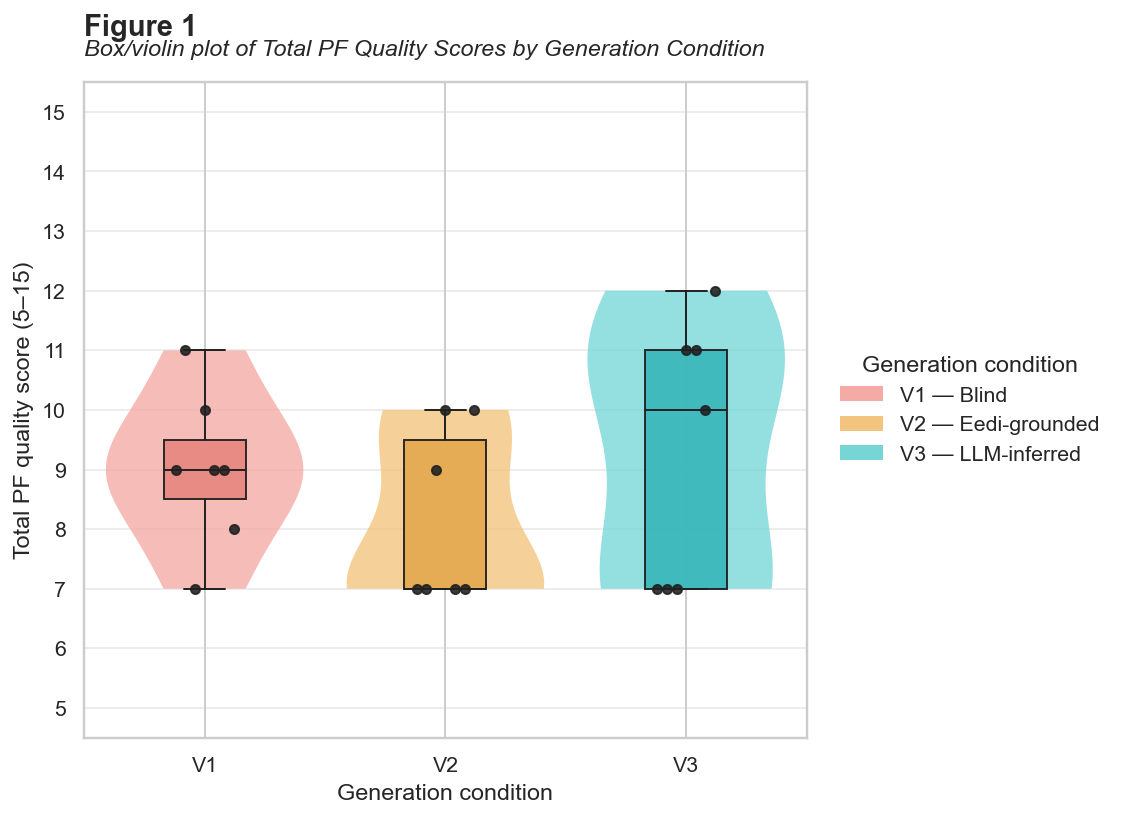

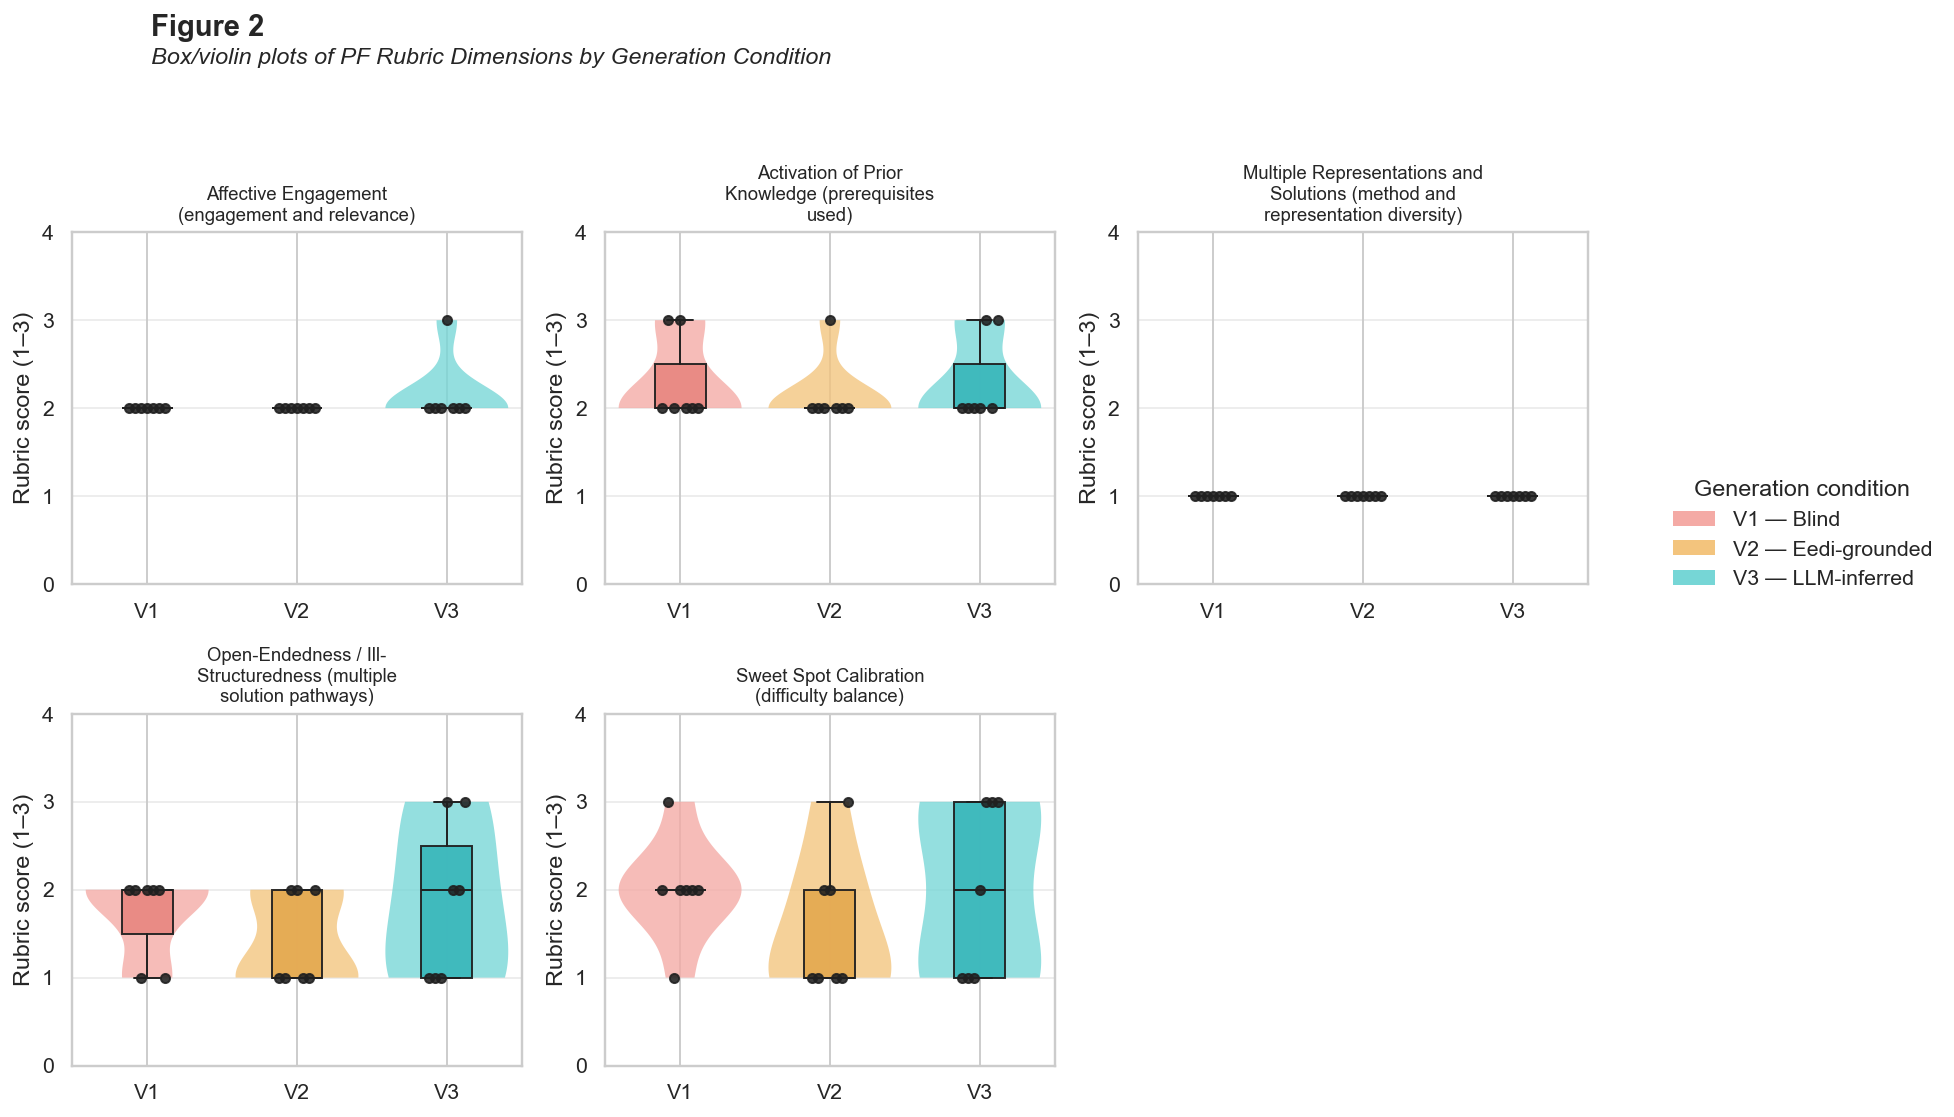

Saved total-score plot to /Users/xuouyu/Desktop/Master Thesis/experiments/results/human_evaluation_total_scores_round1_deepseek.png
Saved dimension plot to /Users/xuouyu/Desktop/Master Thesis/experiments/results/human_evaluation_dimensions_round1_deepseek.png


In [13]:
from pathlib import Path
import textwrap

import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import pandas as pd
import seaborn as sns

pool = globals().get("pool", [])
scores_log = globals().get("scores_log", [])
project_root = globals().get("project_root", Path.cwd().resolve().parent)
model_name = globals().get("MODEL", "unknown")
results_dir = project_root / "experiments" / "results"
results_dir.mkdir(parents=True, exist_ok=True)
condition_order = ["V1", "V2", "V3"]
dimensions = ["APK", "SSC", "AE", "MR", "OE"]
plot_dimensions = ["AE", "APK", "MR", "OE", "SSC"]
condition_labels = {
    "V1": "V1 — Blind",
    "V2": "V2 — Eedi-grounded",
    "V3": "V3 — LLM-inferred",
}
dimension_labels = {
    "APK": "Activation of Prior Knowledge",
    "SSC": "Sweet Spot Calibration",
    "AE": "Affective Engagement",
    "MR": "Multiple Representations and Solutions",
    "OE": "Open-Endedness / Ill-Structuredness",
}
dimension_explanations = {
    "APK": "prerequisites used",
    "SSC": "difficulty balance",
    "AE": "engagement and relevance",
    "MR": "method and representation diversity",
    "OE": "multiple solution pathways",
}

# Use interactive scores when available; otherwise use the completed rubric review
# so the plots can be inspected before participant scoring is entered.
if scores_log:
    df = pd.DataFrame(scores_log)
    score_source = "interactive evaluation scores"
    csv_path = results_dir / "human_scores_round1_deepseek.csv"
elif (results_dir / "agent_scores_round1_deepseek.csv").exists():
    df = pd.read_csv(results_dir / "agent_scores_round1_deepseek.csv")
    score_source = "completed rubric scores"
    csv_path = None
else:
    df = pd.DataFrame()
    score_source = ""
    csv_path = None

if not df.empty:
    df["version"] = pd.Categorical(df["version"], categories=condition_order, ordered=True)
    print(f"Scores used for plots: {len(df)}")
    print(f"Score source: {score_source}")
    print(f"Generator: {model_name}\n")

    print("=== BY VERSION ===")
    summary = df.groupby("version", observed=False)[dimensions + ["TOTAL"]].mean().round(2)
    print(summary.to_string())

    print("\n=== SCORE DISTRIBUTION ===")
    for dim in dimensions:
        counts = df[dim].value_counts().sort_index()
        print(f"{dimension_labels[dim]}: {dict(counts)}")

    print(f"\nMean total PF quality score: {df['TOTAL'].mean():.1f}/15 (SD={df['TOTAL'].std():.1f})")
    if pool and len(df) < len(pool):
        print("\nNote: plots currently show partial scores; score all exercises before using them as final results.")

    sns.set_theme(style="whitegrid", context="notebook")
    violin_palette = {"V1": "#F4AAA5", "V2": "#F3C47D", "V3": "#76D6D6"}
    box_palette = {"V1": "#E98983", "V2": "#E5AA52", "V3": "#3CB8BC"}
    legend_handles = [
        Patch(facecolor=violin_palette[condition], edgecolor="none", label=condition_labels[condition])
        for condition in condition_order
    ]

    def draw_boxviolin(axis, metric, y_limits, y_ticks, ylabel):
        """Draw an explicit paper-style violin + box + black individual points."""
        for position, condition in enumerate(condition_order):
            values = df.loc[df["version"] == condition, metric].dropna().astype(float).tolist()
            if not values:
                continue

            violin = axis.violinplot(
                values, positions=[position], widths=0.82,
                showmeans=False, showmedians=False, showextrema=False,
            )
            for body in violin["bodies"]:
                body.set_facecolor(violin_palette[condition])
                body.set_edgecolor("none")
                body.set_alpha(0.78)

            box = axis.boxplot(
                values, positions=[position], widths=0.34,
                patch_artist=True, showfliers=False,
                medianprops={"color": "#202020", "linewidth": 1.0},
                whiskerprops={"color": "#202020", "linewidth": 1.0},
                capprops={"color": "#202020", "linewidth": 1.0},
                boxprops={"edgecolor": "#202020", "linewidth": 1.0},
            )
            for patch in box["boxes"]:
                patch.set_facecolor(box_palette[condition])
                patch.set_alpha(0.95)

            if len(values) == 1:
                offsets = [0.0]
            else:
                offsets = [-0.12 + 0.24 * index / (len(values) - 1) for index in range(len(values))]
            axis.scatter(
                [position + offset for offset in offsets], values,
                color="#202020", s=22, alpha=0.88, zorder=4,
            )

        axis.set_xticks(range(len(condition_order)))
        axis.set_xticklabels(condition_order)
        axis.set_xlabel("")
        axis.set_ylabel(ylabel)
        axis.set_ylim(*y_limits)
        axis.set_yticks(y_ticks)
        axis.grid(axis="y", alpha=0.35)
        axis.set_axisbelow(True)

    # Figure 1: paper-style total-score box/violin plot.
    fig, axis = plt.subplots(figsize=(8.2, 6.0), dpi=140)
    draw_boxviolin(axis, "TOTAL", (4.5, 15.5), range(5, 16), "Total PF quality score (5–15)")
    axis.set_title("Figure 1", loc="left", fontsize=15, fontweight="bold", pad=24)
    axis.text(
        0.0, 1.035, "Box/violin plot of Total PF Quality Scores by Generation Condition",
        transform=axis.transAxes, fontsize=12, fontstyle="italic", va="bottom",
    )
    axis.set_xlabel("Generation condition")
    axis.legend(handles=legend_handles, title="Generation condition", frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5))
    fig.tight_layout()
    total_plot_path = results_dir / "human_evaluation_total_scores_round1_deepseek.png"
    fig.savefig(total_plot_path, dpi=220, bbox_inches="tight")
    plt.show()

    # Figure 2: paper-style 2×3 grid, matching the reference panel order.
    fig, axes = plt.subplots(2, 3, figsize=(14.5, 8.0), sharey=False, dpi=140)
    for axis, dimension in zip(axes.flat, plot_dimensions):
        draw_boxviolin(axis, dimension, (0, 4), [0, 1, 2, 3, 4], "Rubric score (1–3)")
        title = (
            f"{dimension_labels[dimension]}\n"
            f"({dimension_explanations[dimension]})"
        )
        axis.set_title(textwrap.fill(title, width=28), fontsize=9.5)
    axes[0, 0].set_ylabel("Rubric score (1–3)")
    axes[1, 0].set_ylabel("Rubric score (1–3)")
    axes[1, 2].axis("off")
    fig.suptitle("Figure 2", x=0.08, ha="left", y=0.995, fontsize=15, fontweight="bold")
    fig.text(
        0.08, 0.965, "Box/violin plots of PF Rubric Dimensions by Generation Condition",
        ha="left", va="top", fontsize=12, fontstyle="italic",
    )
    fig.legend(handles=legend_handles, title="Generation condition", frameon=False, loc="center left", bbox_to_anchor=(0.82, 0.53))
    fig.tight_layout(rect=(0, 0, 0.80, 0.93))
    dimensions_plot_path = results_dir / "human_evaluation_dimensions_round1_deepseek.png"
    fig.savefig(dimensions_plot_path, dpi=220, bbox_inches="tight")
    plt.show()

    print(f"Saved total-score plot to {total_plot_path}")
    print(f"Saved dimension plot to {dimensions_plot_path}")

    if csv_path is not None:
        df.to_csv(csv_path, index=False)
        print(f"Saved scores to {csv_path}")
else:
    print("No scores yet. Generate the DeepSeek pool or complete the rubric review first.")

## 4. Agent expert review (separate from participant scores)

This section contains an independent rubric review performed by the coding agent. It must not be merged into `human_scores_round1_deepseek.csv` as if it were a participant rating.

In [4]:
from pathlib import Path

import pandas as pd

agent_review_path = project_root / "experiments" / "results" / "agent_scores_round1_deepseek.csv"
agent_review_df = pd.read_csv(agent_review_path)
print("Agent expert review — not participant human scores")
print(f"Reviewed: {len(agent_review_df)}/{len(pool)}\n")
print(agent_review_df.groupby("version")[["APK", "SSC", "AE", "MR", "OE", "TOTAL"]].mean().round(2).to_string())
print(f"\nSaved at {agent_review_path}")

Agent expert review — not participant human scores
Reviewed: 21/21

          APK   SSC    AE   MR    OE  TOTAL
version                                    
V1       2.29  2.00  2.00  1.0  1.71   9.00
V2       2.14  1.57  2.00  1.0  1.43   8.14
V3       2.29  2.00  2.14  1.0  1.86   9.29

Saved at /Users/xuouyu/Desktop/Master Thesis/experiments/results/agent_scores_round1_deepseek.csv


## 5. Findings from the DeepSeek expert review

### Summary

The fixed DeepSeek pool contains 21 unique exercises: 7 per generation condition. The agent reviewed every exercise using the Rahimi et al. (2025) rubric. These scores are an expert review and are **not participant human-subject data**.

| Condition | APK | SSC | AE | MR | OE | Mean total |
|---|---:|---:|---:|---:|---:|---:|
| V1 | 2.29 | 2.00 | 2.00 | 1.00 | 1.71 | **9.00/15** |
| V2 | 2.14 | 1.57 | 2.00 | 1.00 | 1.43 | **8.14/15** |
| V3 | 2.29 | 2.00 | 2.14 | 1.00 | 1.86 | **9.29/15** |
| **Overall** | **2.24** | **1.86** | **2.05** | **1.00** | **1.67** | **8.81/15** |

> **Preliminary interpretation:** V3 is slightly strongest, followed closely by V1. V2 is weakest in this pool. This is descriptive only; the pool is too small for a statistical claim.

### Stronger examples

**Item 21 — V3: pizza-voucher apportionment — 12/15**

The school must distribute 120 whole-number vouchers in proportion to 60, 45, and 30 participants. Exact proportionality is impossible because the ideal shares are fractional. This creates a genuine productive-failure situation: students must decide how to handle the remainder and justify what “fair” means. It received the strongest `SSC` and `OE` scores in the pool.

**Item 15 — V3: combining two paint mixtures — 11/15**

Two batches use different red-to-yellow ratios and different total volumes. Simply averaging the ratios is plausible but wrong; students must calculate the actual color quantities before combining them. This is a strong weighted-ratio trap with meaningful consequences.

**Item 7 — V1: enlarging a mural — 11/15**

The sketch and wall have incompatible aspect ratios. Students who only multiply one dimension discover that the same scale factor cannot fit both dimensions. The task supports useful reasoning about unit conversion, scale factors, cropping, and distortion.

**Item 14 — V3: splitting a drink into two batches — 11/15**

Students can choose different batch sizes while preserving the same 3:2 ratio. The task is more open-ended than most outputs because multiple valid partitions exist, although the arithmetic remains simple.

### Weaker or invalid examples

**Item 8 — V1: distributing water bottles — 7/15**

The narrative claims that proportional rounding is problematic, but 78:52:65 reduces to 6:4:5 and 30 bottles divide exactly into 12:8:10. The supposed structural trap is therefore absent.

**Item 11 — V3: scale factor for a drawing — 7/15**

The eye implies a scale factor of 60, while the nostril and claw examples imply 30. The data are internally inconsistent, so the student cannot determine one uniquely valid scale factor.

**Item 13 — V2: supplier paint buckets — 7/15**

The solution requires buying 1.2 gallons of yellow and 0.8 gallons of red, but the supplier sells only 5-gallon buckets. The task is infeasible as written.

**Item 19 — V1: combining orange paint batches — 9/15**

The two input batches contain 8 and 6 gallons, but the task refers to a final 12-gallon mixture. The weighted-ratio idea is useful, but the total-volume statement must be corrected.

### Cross-cutting findings

1. **Mathematical coherence needs a separate gate.** Structural validity and section parsing do not detect incorrect totals, impossible purchasing constraints, or inconsistent scale data.
2. **Open-endedness is the main weakness.** Many tasks use verbs such as “design” and “explain,” but still require one predetermined numerical answer.
3. **Multiple representations are missing.** `MR` averaged exactly 1.00 because the student-facing exercises were mostly prose with embedded numbers; tables, diagrams, and explicit representation choices were rarely included.
4. **The pool is now experimentally usable as a fixed dataset.** It is balanced across V1/V2/V3, contains 21 unique visible exercises, and is persisted at [experiments/results/human_evaluation_pool_round1_deepseek.json](experiments/results/human_evaluation_pool_round1_deepseek.json).
5. **The next human-evaluation step should use participant ratings.** The agent review at [experiments/results/agent_scores_round1_deepseek.csv](experiments/results/agent_scores_round1_deepseek.csv) is useful for quality control and item exclusion, but it must not be reported as human-subject evidence.

## 6. Key takeaways compared with Rahimi et al. (2025)

- **V3 is strongest**, followed by V1; V2 is weakest.
- Our total scores are below both reported Rahimi benchmarks.
- The main weakness is **Multiple Representations and Solutions**: all conditions scored 1.
- **Open-Endedness** is also weak; most tasks still lead to one main answer.
- Our exercises activate some prior knowledge, but remain mostly procedural and prose-based.
- These findings are descriptive only: each condition has seven items, and the current scores come from the completed rubric review.